# Paper 11: Attention Is All You Need (The Transformer)
**Authors**: Ashish Vaswani, Noam Shazeer, Niki Parmar, Jakob Uszkoreit, Llion Jones, Aidan N. Gomez, Łukasz Kaiser, Illia Polosukhin (2017)

---

## 1. The Historical Breaking Point: The Recurrence Bottleneck
Before 2017, sequence models relied on recurrent units (LSTMs, GRUs):
- **Sequential Bottleneck ($O(T)$)**: Computing $h_t$ required waiting for $h_{t-1}$, preventing massive parallelization across GPU cores.
- **Gradient Decay**: Long-range credit assignment degraded over multi-step temporal rollouts.

## 2. The First-Principles Breakthrough: Pure Content-Addressed Routing
The Transformer completely eliminates recurrence and convolutions, relying entirely on self-attention:
- **Queries ($Q$)**: What am I searching for?
- **Keys ($K$)**: What do I represent?
- **Values ($V$)**: What content do I pass along?

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q K^T}{\sqrt{d_k}} + M\right) V$$

In this notebook, you will develop and verify:
1. `ScaledDotProductAttention`
2. `MultiHeadAttention`
3. `PositionwiseFeedForward`
4. `PositionalEncoding`
5. `TransformerEncoderLayer` & `TransformerEncoder`
6. `TransformerDecoderLayer` & `TransformerDecoder`
7. Full Seq2Seq `Transformer`

---
## Setup & Autoreload

In [31]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from model import (
    ScaledDotProductAttention,
    MultiHeadAttention,
    PositionwiseFeedForward,
    PositionalEncoding,
    TransformerEncoderLayer,
    TransformerEncoder,
    TransformerDecoderLayer,
    TransformerDecoder,
    Transformer,
)

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
PyTorch version: 2.14.1+cpu
CUDA available: False


---
## 1. Test ScaledDotProductAttention
Verifies shape contracts, attention normalization (rows sum to 1), and masking logic.

In [32]:
torch.manual_seed(42)
attn = ScaledDotProductAttention(dropout=0.0)
attn.eval()

B, H, Tq, Tk, d_k = 2, 4, 8, 8, 32
q = torch.randn(B, H, Tq, d_k)
k = torch.randn(B, H, Tk, d_k)
v = torch.randn(B, H, Tk, d_k)

# Unmasked
out, weights = attn(q, k, v)
print("Output shape:", out.shape)          # Expected: (2, 4, 8, 32)
print("Weights shape:", weights.shape)    # Expected: (2, 4, 8, 8)
assert torch.allclose(weights.sum(dim=-1), torch.ones_like(weights.sum(dim=-1)), atol=1e-5)

# Masked (mask out positions 6 and 7)
mask = torch.ones(B, 1, 1, Tk, dtype=torch.bool)
mask[:, :, :, -2:] = False
out_m, weights_m = attn(q, k, v, mask=mask)
print("Max attention at masked positions:", weights_m[:, :, :, -2:].max().item())
assert (weights_m[:, :, :, -2:] < 1e-4).all()
print("ScaledDotProductAttention PASSED!")

Output shape: torch.Size([2, 4, 8, 32])
Weights shape: torch.Size([2, 4, 8, 8])
Max attention at masked positions: 0.0
ScaledDotProductAttention PASSED!


---
## 2. Test MultiHeadAttention
Verifies linear projections, subspace splitting, and concatenated output projections.

In [33]:
d_model = 64
num_heads = 4
mha = MultiHeadAttention(d_model=d_model, num_heads=num_heads, dropout=0.0)
mha.eval()

B, Tq, Tk = 2, 10, 14
q = torch.randn(B, Tq, d_model)
k = torch.randn(B, Tk, d_model)
v = torch.randn(B, Tk, d_model)

out, weights = mha(q, k, v)
print("Cross-attention output shape:", out.shape)      # (2, 10, 64)
print("Attention weights shape:", weights.shape)       # (2, 4, 10, 14)
assert out.shape == (B, Tq, d_model)
assert weights.shape == (B, num_heads, Tq, Tk)
print("MultiHeadAttention PASSED!")

Cross-attention output shape: torch.Size([2, 10, 64])
Attention weights shape: torch.Size([2, 4, 10, 14])
MultiHeadAttention PASSED!


---
## 3. Visualize Positional Encodings
Sinusoids with geometrically increasing wavelengths provide unique coordinate vectors for each position.

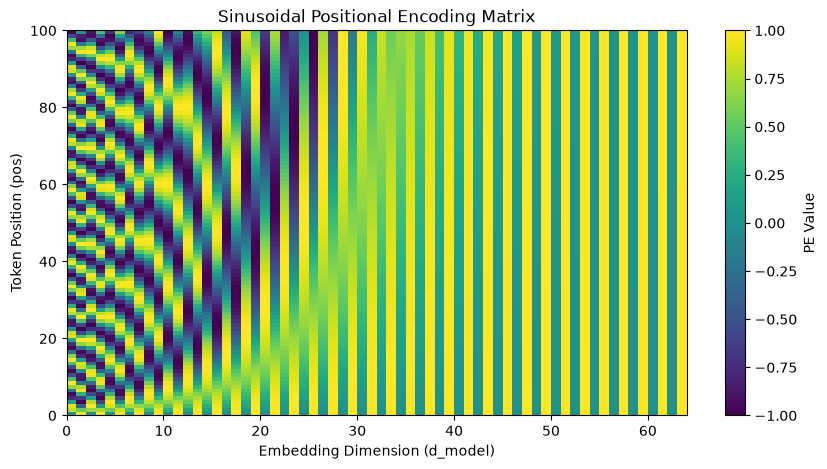

In [34]:
pe_layer = PositionalEncoding(d_model=64, max_len=100, dropout=0.0)
pe_matrix = pe_layer.pe.squeeze(0).cpu().numpy()  # (100, 64)

plt.figure(figsize=(10, 5))
plt.pcolormesh(pe_matrix, cmap='viridis')
plt.xlabel('Embedding Dimension (d_model)')
plt.xlim((0, 64))
plt.ylabel('Token Position (pos)')
plt.colorbar(label='PE Value')
plt.title('Sinusoidal Positional Encoding Matrix')
plt.show()

---
## 4. Test Autoregressive Causal Masking Invariant
Crucial test: Modifying future tokens ($t+1, \dots$) must **NOT** affect the decoder logits at earlier positions ($0, \dots, t$).

In [35]:
torch.manual_seed(42)
src_vocab, trg_vocab = 30, 30
model = Transformer(
    src_vocab_size=src_vocab,
    trg_vocab_size=trg_vocab,
    d_model=32,
    num_heads=2,
    num_encoder_layers=2,
    num_decoder_layers=2,
    d_ff=64,
    dropout=0.0,
)
model.eval()

src = torch.randint(1, src_vocab, (1, 6))
trg1 = torch.tensor([[1, 5, 9, 12, 18, 22]])
# trg2 shares first 3 tokens with trg1, but changes future tokens
trg2 = torch.tensor([[1, 5, 9, 25, 27, 28]])

causal_mask = Transformer.generate_square_subsequent_mask(trg1.size(1))

with torch.no_grad():
    out1 = model(src, trg1, trg_mask=causal_mask)
    out2 = model(src, trg2, trg_mask=causal_mask)

diff = (out1[:, :3, :] - out2[:, :3, :]).abs().max().item()
print(f"Difference in first 3 positions: {diff:.2e}")
assert diff < 1e-4, f"Causal leak detected! diff={diff}"
print("Causal Masking Autoregressive Invariant PASSED!")

Difference in first 3 positions: 0.00e+00
Causal Masking Autoregressive Invariant PASSED!


---
## 5. Single Batch Overfit: Sequence Inversion
Train the model to invert a sequence of tokens within 80 steps to verify gradient flow across all modules.

Epoch  20 | Loss: 0.2640
Epoch  40 | Loss: 0.0695
Epoch  60 | Loss: 0.0389
Epoch  80 | Loss: 0.0268
Epoch 100 | Loss: 0.0202


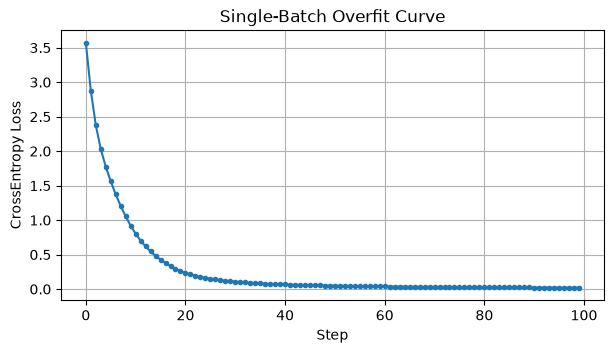

Overfit check PASSED! Final loss: 0.0202


In [36]:
torch.manual_seed(42)
B, T_src, T_trg, vocab_size = 2, 6, 6, 25

model = Transformer(
    src_vocab_size=vocab_size,
    trg_vocab_size=vocab_size,
    d_model=64,
    num_heads=4,
    num_encoder_layers=2,
    num_decoder_layers=2,
    d_ff=128,
    dropout=0.0,
)
optimizer = optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

src = torch.randint(1, vocab_size, (B, T_src))
trg_in = torch.cat([torch.zeros(B, 1, dtype=torch.long), torch.flip(src, dims=[1])[:, :-1]], dim=1)
trg_target = torch.flip(src, dims=[1])
trg_mask = Transformer.generate_square_subsequent_mask(T_trg)

losses = []
for epoch in range(100):
    optimizer.zero_grad()
    logits = model(src, trg_in, trg_mask=trg_mask)
    loss = criterion(logits.reshape(-1, vocab_size), trg_target.reshape(-1))
    loss.backward()
    optimizer.step()
    losses.append(loss.item())
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1:3d} | Loss: {loss.item():.4f}")

plt.figure(figsize=(7, 3.5))
plt.plot(losses, marker='o', markersize=3)
plt.xlabel('Step')
plt.ylabel('CrossEntropy Loss')
plt.title('Single-Batch Overfit Curve')
plt.grid(True)
plt.show()

assert losses[-1] < 0.1
print(f"Overfit check PASSED! Final loss: {losses[-1]:.4f}")